# Randomized Block Design (RBD) Analysis
## Comparison of Five Strategies Across Four Workloads

**Significance level:** $\alpha = 0.05$

## Objective
Determine whether mean performance differs among the five strategies while accounting for variation between workloads.

## Experimental design
- **Treatments:** Five strategies
- **Blocks:** Four workloads
- **Response variable:** Performance
- **Design:** Randomized Complete Block Design, with one observation for each strategy–workload combination.

The analysis uses an additive model with strategy and workload main effects. Since there is one observation per combination, the strategy-by-workload interaction cannot be estimated separately from the error term.


## Step 1 — Enter the data

The observations are entered with strategies as rows and workloads as columns. The values are taken directly from the question.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

alpha = 0.05

data = np.array([
    [68, 79, 93, 87],
    [72, 80, 89, 95],
    [73, 80, 88, 94],
    [81, 88, 95, 100],
    [82, 92, 97, 102]
])

strategies = [f"Strategy {i}" for i in range(1, 6)]
workloads = [f"Workload {i}" for i in range(1, 5)]

wide_df = pd.DataFrame(data, index=strategies, columns=workloads)
display(wide_df)


,Workload 1,Workload 2,Workload 3,Workload 4
Strategy 1,68,79,93,87
Strategy 2,72,80,89,95
Strategy 3,73,80,88,94
Strategy 4,81,88,95,100
Strategy 5,82,92,97,102


## Step 2 — Arrange the data

The data are converted to long format, with one row for each observation and separate columns for performance, strategy, and workload.


In [2]:
df = (
    wide_df.rename_axis("Strategy")
    .reset_index()
    .melt(id_vars="Strategy", var_name="Workload", value_name="Performance")
)

df["Strategy"] = pd.Categorical(df["Strategy"], categories=strategies, ordered=True)
df["Workload"] = pd.Categorical(df["Workload"], categories=workloads, ordered=True)

display(df)
print(f"Number of observations: {len(df)}")
print(f"Number of strategies: {df['Strategy'].nunique()}")
print(f"Number of workloads (blocks): {df['Workload'].nunique()}")


,Strategy,Workload,Performance
0,Strategy 1,Workload 1,68
1,Strategy 2,Workload 1,72
2,Strategy 3,Workload 1,73
3,Strategy 4,Workload 1,81
4,Strategy 5,Workload 1,82
5,Strategy 1,Workload 2,79
6,Strategy 2,Workload 2,80
7,Strategy 3,Workload 2,80
8,Strategy 4,Workload 2,88
9,Strategy 5,Workload 2,92


Number of observations: 20
Number of strategies: 5
Number of workloads (blocks): 4


## Step 3 — Hypotheses

The hypotheses for the strategy effect are:

- **Null hypothesis (H₀):** $\mu_1 = \mu_2 = \mu_3 = \mu_4 = \mu_5$
- **Alternative hypothesis (H₁):** At least one strategy mean differs.

The test is conducted at $\alpha = 0.05$. Workload is included as a blocking factor.


## Step 4 — Descriptive statistics

Calculate the mean performance for each strategy and each workload. These summaries provide an initial comparison before conducting the ANOVA.


In [3]:
strategy_means = df.groupby("Strategy", observed=False)["Performance"].mean()
workload_means = df.groupby("Workload", observed=False)["Performance"].mean()

print("Mean performance by strategy:")
display(strategy_means.to_frame("Mean Performance"))

print("Mean performance by workload (block):")
display(workload_means.to_frame("Mean Performance"))

print(f"Overall mean performance: {df['Performance'].mean():.2f}")


Mean performance by strategy:


,Mean Performance
Strategy,
Strategy 1,81.75
Strategy 2,84.00
Strategy 3,83.75
Strategy 4,91.00
Strategy 5,93.25


Mean performance by workload (block):


,Mean Performance
Workload,
Workload 1,75.2
Workload 2,83.8
Workload 3,92.4
Workload 4,95.6


Overall mean performance: 86.75


## Step 5 — Comparison of strategy means

The plot displays the observed mean performance for each strategy.


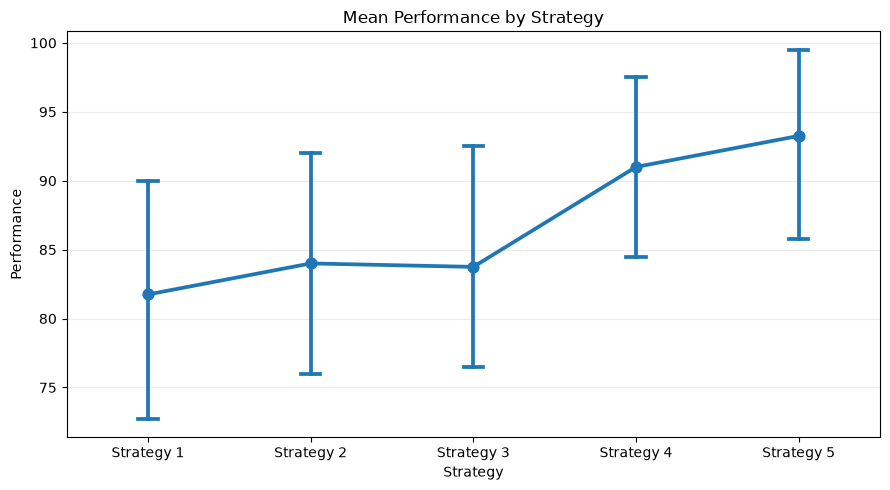

In [4]:
plt.figure(figsize=(9, 5))
sns.pointplot(data=df, x="Strategy", y="Performance", errorbar=("ci", 95), capsize=0.12)
plt.title("Mean Performance by Strategy")
plt.xlabel("Strategy")
plt.ylabel("Performance")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Step 6 — Fit the RBD model

The additive Randomized Block Design model is:

$$
Y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}
$$

where:

- $Y_{ij}$ is the observed performance of strategy $i$ under workload $j$.
- $\mu$ is the **grand mean**, calculated across all 20 observations.
- $\tau_i$ is the effect of strategy $i$.
- $\beta_j$ is the effect of workload $j$ (the block effect).
- $\varepsilon_{ij}$ is the random error for that observation.

The model includes the strategy and workload main effects.


In [5]:
model = smf.ols("Performance ~ C(Strategy) + C(Workload)", data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

display(anova_table)


,sum_sq,df,F,PR(>F)
C(Strategy),407.50,4.0,16.862069,7.235445e-05
C(Workload),1261.75,3.0,69.613793,7.370564e-08
Residual,72.50,12.0,NaN,NaN


## Step 7 — ANOVA decision

Use the p-value for Strategy in the ANOVA table.

- If the p-value is less than 0.05, reject H₀.
- If the p-value is greater than or equal to 0.05, fail to reject H₀.

The workload effect accounts for systematic differences between workloads. The main research question concerns the strategy effect.


In [6]:
strategy_row = anova_table.loc["C(Strategy)"]
strategy_f = strategy_row["F"]
strategy_p = strategy_row["PR(>F)"]

print(f"Strategy F-statistic: {strategy_f:.4f}")
print(f"Strategy p-value: {strategy_p:.8f}")
print(f"Significance level: {alpha:.2f}")

if strategy_p < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Conclusion: There is statistically significant evidence that mean performance differs among the five strategies.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Conclusion: There is not sufficient statistical evidence that mean performance differs among the five strategies.")


Strategy F-statistic: 16.8621
Strategy p-value: 0.00007235
Significance level: 0.05

Decision: Reject the null hypothesis.
Conclusion: There is statistically significant evidence that mean performance differs among the five strategies.


## Step 8 — Check model assumptions

The RBD ANOVA assumptions are:
1. Errors are independent.
2. Errors are approximately normally distributed.
3. Error variance is approximately constant.

The residual plots are used to assess these assumptions.


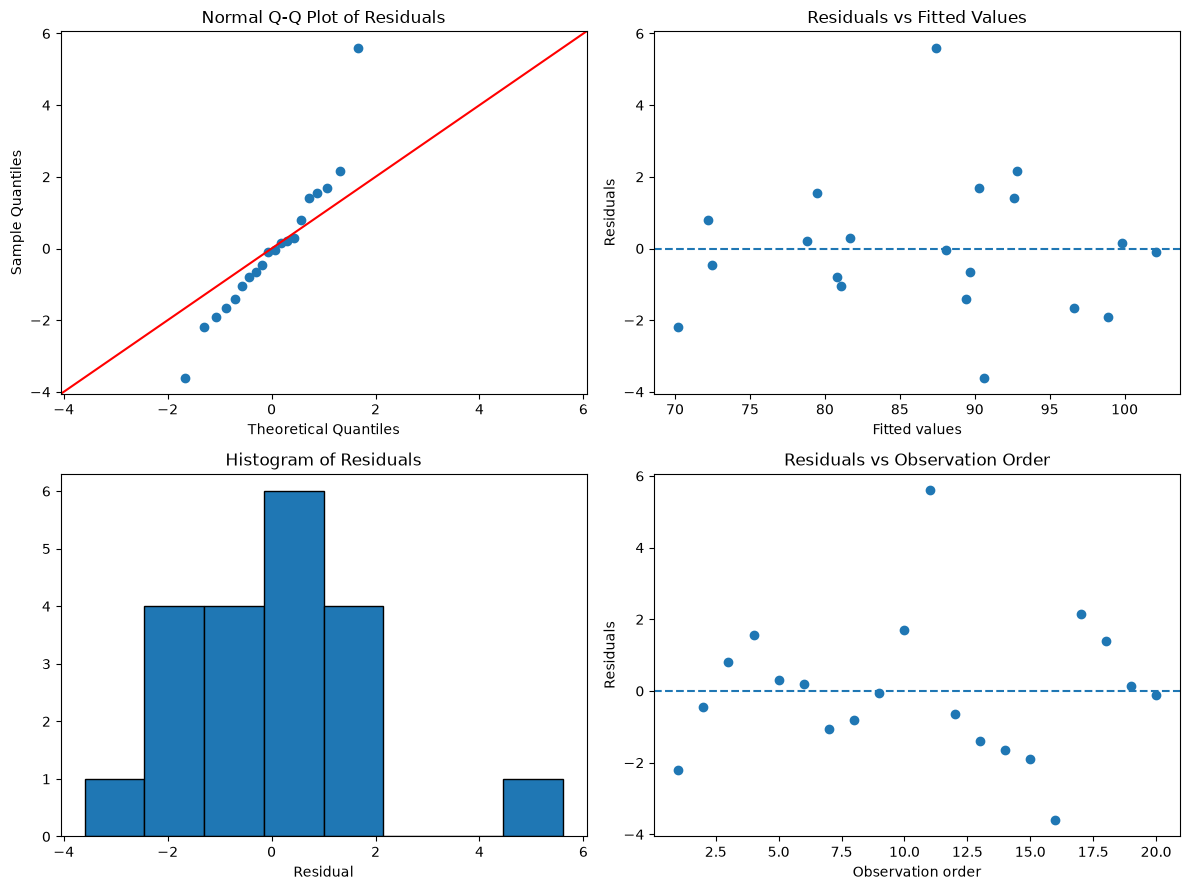

In [7]:
residuals = model.resid
fitted = model.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sm.qqplot(residuals, line="45", ax=axes[0, 0])
axes[0, 0].set_title("Normal Q-Q Plot of Residuals")

axes[0, 1].scatter(fitted, residuals)
axes[0, 1].axhline(0, linestyle="--")
axes[0, 1].set_title("Residuals vs Fitted Values")
axes[0, 1].set_xlabel("Fitted values")
axes[0, 1].set_ylabel("Residuals")

axes[1, 0].hist(residuals, bins=8, edgecolor="black")
axes[1, 0].set_title("Histogram of Residuals")
axes[1, 0].set_xlabel("Residual")

axes[1, 1].scatter(np.arange(1, len(residuals) + 1), residuals)
axes[1, 1].axhline(0, linestyle="--")
axes[1, 1].set_title("Residuals vs Observation Order")
axes[1, 1].set_xlabel("Observation order")
axes[1, 1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()


### Normality test

The Shapiro–Wilk test assesses whether the residuals are consistent with a normal distribution.

- **H₀:** Residuals follow a normal distribution.
- **H₁:** Residuals do not follow a normal distribution.

Interpret the test together with the normal probability plot.


In [8]:
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Shapiro-Wilk statistic: {shapiro_stat:.4f}")
print(f"Shapiro-Wilk p-value: {shapiro_p:.4f}")

if shapiro_p < alpha:
    print("The test indicates evidence against normality at the 0.05 level.")
else:
    print("The test does not provide sufficient evidence against normality at the 0.05 level.")


Shapiro-Wilk statistic: 0.9409
Shapiro-Wilk p-value: 0.2491
The test does not provide sufficient evidence against normality at the 0.05 level.


## Step 9 — Multiple comparisons

If the overall strategy effect is significant, pairwise comparisons are used to identify which strategy means differ.

The comparisons use the residual mean square and error degrees of freedom from the blocked ANOVA model. The Tukey procedure controls the family-wise error rate at 0.05.


In [9]:
if strategy_p < alpha:
    from itertools import combinations

    mse = anova_table.loc["Residual", "sum_sq"] / anova_table.loc["Residual", "df"]
    error_df = int(anova_table.loc["Residual", "df"])
    n_blocks = len(workloads)
    q_critical = stats.studentized_range.ppf(1 - alpha, len(strategies), error_df)
    standard_error = np.sqrt(mse / n_blocks)

    comparisons = []
    for s1, s2 in combinations(strategies, 2):
        mean_diff = strategy_means.loc[s1] - strategy_means.loc[s2]
        q_stat = abs(mean_diff) / standard_error
        p_adj = stats.studentized_range.sf(q_stat, len(strategies), error_df)
        lower = mean_diff - q_critical * standard_error
        upper = mean_diff + q_critical * standard_error

        comparisons.append({
            "Strategy 1": s1,
            "Strategy 2": s2,
            "Mean Difference (1 - 2)": mean_diff,
            "Lower 95% Simultaneous CI": lower,
            "Upper 95% Simultaneous CI": upper,
            "Adjusted p-value": p_adj,
            "Significant": p_adj < alpha
        })

    tukey_results = pd.DataFrame(comparisons)
    display(tukey_results.round(4))
else:
    print("The overall strategy effect is not significant. Pairwise follow-up comparisons are not performed.")


,Strategy 1,Strategy 2,Mean Difference (1 - 2),Lower 95% Simultaneous CI,Upper 95% Simultaneous CI,Adjusted p-value,Significant
0,Strategy 1,Strategy 2,-2.25,-7.7899,3.2899,0.6993,False
1,Strategy 1,Strategy 3,-2.00,-7.5399,3.5399,0.7776,False
2,Strategy 1,Strategy 4,-9.25,-14.7899,-3.7101,0.0014,True
3,Strategy 1,Strategy 5,-11.50,-17.0399,-5.9601,0.0002,True
4,Strategy 2,Strategy 3,0.25,-5.2899,5.7899,0.9999,False
5,Strategy 2,Strategy 4,-7.00,-12.5399,-1.4601,0.0118,True
6,Strategy 2,Strategy 5,-9.25,-14.7899,-3.7101,0.0014,True
7,Strategy 3,Strategy 4,-7.25,-12.7899,-1.7101,0.0093,True
8,Strategy 3,Strategy 5,-9.50,-15.0399,-3.9601,0.0011,True
9,Strategy 4,Strategy 5,-2.25,-7.7899,3.2899,0.6993,False


## Step 10 — Conclusion

Use the ANOVA p-value for Strategy to answer the research question. If the result is significant, use the pairwise comparison table to identify which strategies differ.


In [10]:
print("FINAL RBD SUMMARY")
print("-----------------")
print(f"Number of strategies: {len(strategies)}")
print(f"Number of blocks: {len(workloads)}")
print(f"Strategy F({int(strategy_row['df'])}, {int(anova_table.loc['Residual', 'df'])}) = {strategy_f:.4f}")
print(f"Strategy p-value = {strategy_p:.8f}")
print(f"Alpha = {alpha:.2f}")

if strategy_p < alpha:
    print("Decision: Reject H0.")
    print("Final conclusion: Mean performance is not the same for all five strategies.")
    print("Refer to the Tukey table to identify the strategy pairs that differ.")
else:
    print("Decision: Fail to reject H0.")
    print("Final conclusion: There is insufficient evidence of a difference in mean performance among the five strategies.")


FINAL RBD SUMMARY
-----------------
Number of strategies: 5
Number of blocks: 4
Strategy F(4, 12) = 16.8621
Strategy p-value = 0.00007235
Alpha = 0.05
Decision: Reject H0.
Final conclusion: Mean performance is not the same for all five strategies.
Refer to the Tukey table to identify the strategy pairs that differ.
